# 01 — Pilot data quality

This notebook profiles the largest locally available Phase 1 pilot. It reports sample diagnostics only; it does not treat the pilot as a population census. Run it from the repository root.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'config' / 'topics.yaml').exists():
    ROOT = ROOT.parent.resolve()
sys.path.insert(0, str(ROOT / 'src'))

from ai_research_trends.config import load_config
from ai_research_trends.crawling.profile_pilot import profile

In [2]:
candidates = list((ROOT / 'data' / 'interim').glob('pilot_*/works.jsonl'))
if not candidates:
    raise FileNotFoundError('No pilot JSONL found. Run openalex-collect-pilot first.')
pilot_path = max(candidates, key=lambda path: (path.stat().st_size, path.stat().st_mtime))
quality = profile(pilot_path, load_config(ROOT / 'config' / 'topics.yaml'))
pd.Series({
    'source': str(pilot_path.relative_to(ROOT)),
    'records': quality['records'],
    'unique_work_ids': quality['unique_canonical_work_ids'],
    'duplicate_work_ids': quality['duplicate_canonical_work_ids'],
    'languages_available': quality['language_available_count'],
}, name='value').to_frame()

,value
source,data/interim/pilot_20261019T024131Z/works.jsonl
records,1000
unique_work_ids,1000
duplicate_work_ids,0
languages_available,948


In [3]:
missing = pd.Series(quality['missing_count'], name='missing_count').to_frame()
missing['missing_percent'] = 100 * missing['missing_count'] / quality['records']
missing.sort_values('missing_percent', ascending=False)

,missing_count,missing_percent
fwci,234,23.4
abstract_inverted_index,194,19.4
doi,90,9.0
language,52,5.2
authorships,5,0.5
title,0,0.0
topics,0,0.0
primary_topic,0,0.0
cited_by_count,0,0.0
open_access,0,0.0


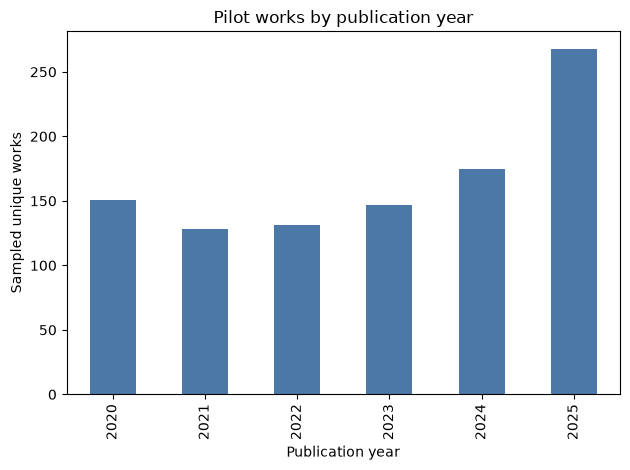

In [4]:
years = pd.Series(quality['publication_year'], dtype='int64').sort_index()
ax = years.plot.bar(title='Pilot works by publication year', color='#4C78A8')
ax.set_xlabel('Publication year')
ax.set_ylabel('Sampled unique works')
plt.tight_layout();

In [5]:
pd.Series(quality['citation_distribution'], name='value').to_frame()

,value
available_count,1000.000
missing_count,0.000
zero_count,377.000
minimum,0.000
median,1.000
mean,9.633
p90_linear,20.000
maximum,894.000


In [6]:
category_counts = pd.concat(
    {layer: pd.Series(counts) for layer, counts in quality['category_match_count'].items()},
    names=['analytical_layer', 'research_category'],
).rename('matches').to_frame()
category_counts.sort_values('matches', ascending=False)

matches
analytical_layer research_category                                
openalex_native  computer_vision                               135
                 natural_language_processing                   108
custom_emerging  large_language_models                          53
openalex_native  reinforcement_learning                         47
                 multimodal_machine_learning_applications       39
                 explainable_ai                                 28
custom_emerging  multimodal_ai                                  15
                 retrieval_augmented_generation                  4

In [7]:
pd.Series(quality['language_count'], name='works').head(20).to_frame()

,works
en,879
id,16
es,7
ru,7
ja,6
ar,6
pt,4
tr,4
de,4
ko,3


## Interpretation constraints

Category rows overlap. Missing affiliation/country values must remain in denominator reporting. Citation counts are age-dependent and skewed; they are not measures of scientific quality.